# Market Visualizations

Translating our statistical findings from Notebook 02 into executive visuals across all three business questions.

In [37]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

figure_dir = '../reports/figures'
os.makedirs(figure_dir, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')

plt.rcParams.update({
    # Figure Size
    'figure.figsize': (11, 6),
    'figure.dpi': 120,
    'figure.autolayout': True,
    
    # Title Style
    'axes.titlelocation': 'left',
    'axes.titlesize': 13.5,
    'axes.titleweight': 'bold',
    'axes.titlecolor': '#111111',
    'axes.titlepad': 24,
    
    # Axis Labels & Ticks
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'axes.labelcolor': '#222222',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10.5,
    
    # Clean Spines & Grid
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.color': '#e0e0e0',
    'grid.linestyle': '--',
    'grid.alpha': 0.7,
    
    # Legend Default
    'legend.frameon': False,
    'legend.fontsize': 10.5,
    
    # Export Default
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})


tier_colors = {
    '1. Top 10 Giants': '#1f4e78',
    '2. Mid-Tier (Rank 11-50)': '#4bacc6',
    '3. Small/Niche (Rank 51-232)': '#d9d9d9'
}

# Helper fun for title & subtitle
def set_header(ax, title, subtitle=None):
    ax.set_title(title)
    if subtitle:
        ax.text(0, 1.03, subtitle, transform=ax.transAxes, 
                fontsize=10.5, color='#555555', ha='left')

df = pd.read_csv('../data/processed/master_medicines_enriched.csv')
display(df.head())


,brand_id,brand_name,type,slug,dosage_form,generic,strength,manufacturer,package_container,price_bdt,pricing_basis,generic_id,drug_class,indication,mfg_tier,competition_tier,pricing_stance,price_to_median_ratio
0,4077,A-Cold,allopathic,a-coldsyrup4-mg5-ml,Syrup,Bromhexine Hydrochloride,4 mg/5 ml,ACME Laboratories Ltd.,100 ml bottle: ৳ 40.12,40.12,per_container,145,Cough expectorants & mucolytics,Bronchitis,1. Top 10 Giants,4. Crowded (11+ Mfgs),Not Applicable (Non-Unit / <10 Brands),NaN
1,4006,A-Cof,allopathic,a-cofsyrup10-mg30-mg125-mg5-ml,Syrup,Dextromethorphan + Pseudoephedrine + Triprolidine,(10 mg+30 mg+1.25 mg)/5 ml,ACME Laboratories Ltd.,100 ml bottle: ৳ 100.00,100.00,per_container,346,Combined cough suppressants,Non-productive cough,1. Top 10 Giants,4. Crowded (11+ Mfgs),Not Applicable (Non-Unit / <10 Brands),NaN
2,6174,A-Clox,allopathic,a-cloxinjection500-mgvial,Injection,Cloxacillin Sodium,500 mg/vial,ACME Laboratories Ltd.,"500 mg vial: ৳ 28.43,(5's pack: ৳ 142.15),",28.43,per_container,292,Penicillinase-resistant penicillins,UTI caused by Staphylococcus Aureus,1. Top 10 Giants,4. Crowded (11+ Mfgs),Not Applicable (Non-Unit / <10 Brands),NaN
3,6173,A-Clox,allopathic,a-cloxinjection250-mgvial,Injection,Cloxacillin Sodium,250 mg/vial,ACME Laboratories Ltd.,"250 mg vial: ৳ 20.00,(5's pack: ৳ 100.00),",20.00,per_container,292,Penicillinase-resistant penicillins,UTI caused by Staphylococcus Aureus,1. Top 10 Giants,4. Crowded (11+ Mfgs),Not Applicable (Non-Unit / <10 Brands),NaN
4,6172,A-Clox,allopathic,a-cloxpowder-for-suspension125-mg5-ml,Powder for Suspension,Cloxacillin Sodium,125 mg/5 ml,ACME Laboratories Ltd.,100 ml bottle: ৳ 45.00,45.00,per_container,292,Penicillinase-resistant penicillins,UTI caused by Staphylococcus Aureus,1. Top 10 Giants,4. Crowded (11+ Mfgs),Not Applicable (Non-Unit / <10 Brands),NaN


---
## Visual 1: Manufacturing barriers to entry by dosage form

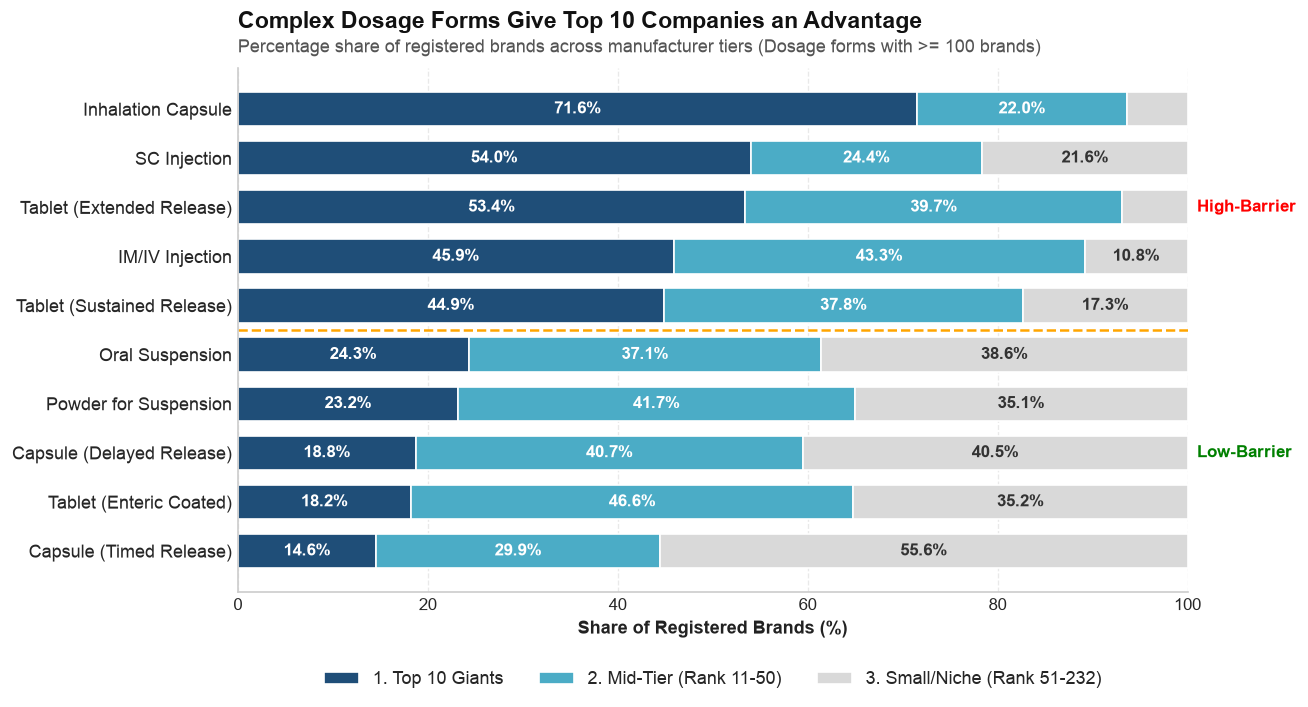

In [51]:
dosage_form_analysis = pd.crosstab(
    df['dosage_form'],
    df['mfg_tier'],
    normalize='index'
) * 100
dosage_form_analysis['total_brands'] = df['dosage_form'].value_counts()
# display(dosage_form_analysis.head())

major_forms = dosage_form_analysis[
    dosage_form_analysis['total_brands'] >= 100].sort_values(by='1. Top 10 Giants', ascending=True)

# 5 highest & lowest barrier
selected_forms = pd.concat([major_forms.head(5), major_forms.tail(5)])
# display(selected_forms)

tier_cols = ['1. Top 10 Giants', '2. Mid-Tier (Rank 11-50)', '3. Small/Niche (Rank 51-232)']

fig, ax = plt.subplots()

left = np.zeros(len(selected_forms)) #10
for tier in tier_cols:
    values = selected_forms[tier].values
    bars = ax.barh(
        selected_forms.index,
        values,
        left=left,
        label=tier,
        color=tier_colors[tier],
        edgecolor='white',
        height=0.70
    )
    for i, val in enumerate(values):
        if val >= 8:
            text_color = 'white' if tier != '3. Small/Niche (Rank 51-232)' else '#333333'
            ax.text(left[i] + val / 2, i, f"{val:.1f}%", va='center', ha='center', 
                    color=text_color, fontweight='bold', fontsize=10)
    left += values


ax.axhline(4.5, color='orange', linestyle='--', linewidth=1.5)
ax.text(101, 7.0, 'High-Barrier', color='red', fontweight='bold', va='center', fontsize=10)
ax.text(101, 2.0, 'Low-Barrier', color='green', fontweight='bold', va='center', fontsize=10)

ax.set_xlim(0, 100)
ax.set_xlabel('Share of Registered Brands (%)')

set_header(
    ax, 
    title='Complex Dosage Forms Give Top 10 Companies an Advantage',
    subtitle='Percentage share of registered brands across manufacturer tiers (Dosage forms with >= 100 brands)'
)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)

plt.savefig(f"{figure_dir}/01_dosage_form_barriers_by_tier.png")
plt.show()
